In [1]:
import cv2 as cv
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']

In [2]:
def getLabels():
    class_names = []
    with open('className.txt', 'r') as file_handler:
        for item in file_handler.readlines():
            class_names.append("{}".format(item[:len(item)-1]))
    return class_names

In [3]:
# 处理第一张图片
image = cv.imread('./tmp/test1.png', cv.IMREAD_GRAYSCALE)
image = cv.resize(image, (28, 28))
image = image / 255.0
image = np.reshape(image, [28, 28, 1])
image = np.expand_dims(image, axis=0)

# 处理第二张图片
image2 = cv.imread('./tmp/test2.png', cv.IMREAD_GRAYSCALE)
image2 = cv.resize(image2, (28, 28))
image2 = image2 / 255.0
image2 = np.reshape(image2, [28, 28, 1])
image2 = np.expand_dims(image2, axis=0)

1/1 [==============================] - 1s 503ms/step
book


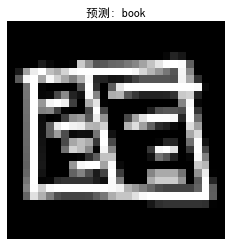

1/1 [==============================] - 0s 52ms/step
key


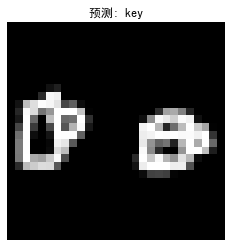

In [4]:
# 加载模型
model = tf.keras.models.load_model('./saved_model/model_quickdraw.h5')
labels = getLabels()

# 预测并输出结果
pred1 = model.predict(image)
print(labels[np.argmax(pred1[0])])
plt.imshow(image.reshape(28, 28), cmap='gray')
plt.title(f'预测: {labels[np.argmax(pred1[0])]}')
plt.axis('off')
plt.show()

pred2 = model.predict(image2)
print(labels[np.argmax(pred2[0])])
plt.imshow(image2.reshape(28, 28), cmap='gray')
plt.title(f'预测: {labels[np.argmax(pred2[0])]}')
plt.axis('off')
plt.show()